In [170]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [171]:
df = pd.read_csv('../Files/titanic_data_updated.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [172]:
df.drop(['PassengerId','Name','Ticket'], axis=1, inplace=True)


In [173]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S


In [174]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

In [175]:
# df.drop(['Cabin'], axis=1, inplace=True)


In [176]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


In [177]:
X = df.drop(['Survived'], axis=1)

X

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,third,male,22.0,1,0,7.2500,NaN,S
1,first,female,38.0,1,0,71.2833,C85,C
2,third,female,26.0,0,0,7.9250,NaN,S
3,first,female,35.0,1,0,53.1000,C123,S
4,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,NaN,S
887,first,female,19.0,0,0,30.0000,B42,S
888,third,female,NaN,1,2,23.4500,NaN,S
889,first,male,26.0,0,0,30.0000,C148,C


In [178]:
y = df['Survived']
y

0       no
1      yes
2      yes
3      yes
4       no
      ... 
886     no
887    yes
888     no
889    yes
890     no
Name: Survived, Length: 891, dtype: object

In [179]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=.2, random_state=42)


In [180]:
# X_train
# X_test.shape
display(y_train)

331     no
733     no
382     no
704     no
813     no
      ... 
106    yes
270     no
860     no
435    yes
102     no
Name: Survived, Length: 712, dtype: object

In [181]:
X_train.isnull().sum()

Pclass        0
Sex           0
Age         140
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      2
dtype: int64

In [182]:
X_test.isnull().sum()

Pclass        0
Sex           0
Age          37
SibSp         0
Parch         0
Fare          0
Cabin       134
Embarked      0
dtype: int64

In [183]:
# mean impute
age_mean = X_train['Age'].mean()

X_train['Age_mean_imputer'] = X_train['Age'].fillna(age_mean)
X_test['Age_mean_imputer'] = X_test['Age'].fillna(age_mean)

X_train.isnull().sum()
X_test.isnull().sum()

Pclass                0
Sex                   0
Age                  37
SibSp                 0
Parch                 0
Fare                  0
Cabin               134
Embarked              0
Age_mean_imputer      0
dtype: int64

In [184]:
# median impute
age_median = X_train['Age'].median()

X_train['Age_median_imputer'] = X_train['Age'].fillna(age_median)
X_test['Age_median_imputer'] = X_test['Age'].fillna(age_median)

X_train.isnull().sum()
X_test.isnull().sum()

Pclass                  0
Sex                     0
Age                    37
SibSp                   0
Parch                   0
Fare                    0
Cabin                 134
Embarked                0
Age_mean_imputer        0
Age_median_imputer      0
dtype: int64

In [185]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,Age_mean_imputer,Age_median_imputer
331,first,male,45.5,0,0,28.5000,C124,S,45.500000,45.5
733,second,male,23.0,0,0,13.0000,NaN,S,23.000000,23.0
382,third,male,32.0,0,0,7.9250,NaN,S,32.000000,32.0
704,third,male,26.0,1,0,7.8542,NaN,S,26.000000,26.0
813,third,female,6.0,4,2,31.2750,NaN,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S,21.000000,21.0
270,first,male,NaN,0,0,31.0000,NaN,S,29.498846,28.0
860,third,male,41.0,2,0,14.1083,NaN,S,41.000000,41.0
435,first,female,14.0,1,2,120.0000,B96 B98,S,14.000000,14.0


<Axes: xlabel='Age_mean_imputer', ylabel='Density'>

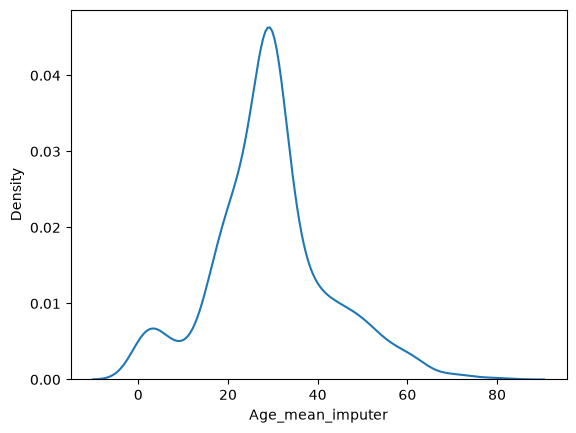

In [186]:
sns.kdeplot(data=X_train, x='Age_mean_imputer')

<Axes: xlabel='Age_median_imputer', ylabel='Density'>

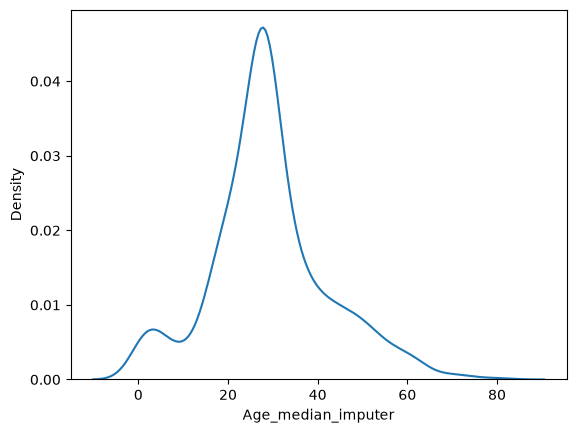

In [187]:
sns.kdeplot(data=X_train, x='Age_median_imputer')


In [188]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
age_imputer.fit(X_train[['Age']])

X_train['Age'] = age_imputer.transform(X_train[['Age']]).ravel()

In [189]:
X_train.isnull().sum()
X_train.drop(['Age_mean_imputer', 'Age_median_imputer'], axis=1, inplace=True)
X_test.drop(['Age_mean_imputer', 'Age_median_imputer'], axis=1, inplace=True)

In [190]:
X_train.isnull().sum()

Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      2
dtype: int64

In [191]:
X_test['Age'] = age_imputer.transform(X_test[['Age']])

In [192]:
X_test.isnull().sum()


Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Cabin       134
Embarked      0
dtype: int64

In [193]:
embarked_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
embarked_imputer.fit(X_train[['Embarked']])

# transform both train and test data
X_train['Embarked'] = embarked_imputer.transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_imputer.transform(X_test[['Embarked']]).ravel()

X_train.isnull().sum()

Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      0
dtype: int64

In [194]:
cabin_imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Missing',add_indicator=True)
cabin_imputer.fit(X_train[['Cabin']])

#? transform both train and test data
X_train[['Cabin','Cabin_Missing_Indicator']]= cabin_imputer.transform(X_train[['Cabin']])
X_test[['Cabin','Cabin_Missing_Indicator']] = cabin_imputer.transform(X_test[['Cabin']])


In [195]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,Cabin_Missing_Indicator
331,first,male,45.500000,0,0,28.5000,C124,S,False
733,second,male,23.000000,0,0,13.0000,Missing,S,True
382,third,male,32.000000,0,0,7.9250,Missing,S,True
704,third,male,26.000000,1,0,7.8542,Missing,S,True
813,third,female,6.000000,4,2,31.2750,Missing,S,True
...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,Missing,S,True
270,first,male,29.498846,0,0,31.0000,Missing,S,True
860,third,male,41.000000,2,0,14.1083,Missing,S,True
435,first,female,14.000000,1,2,120.0000,B96 B98,S,False


In [196]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,Cabin_Missing_Indicator
709,third,male,29.498846,1,1,15.2458,Missing,C,True
439,second,male,31.000000,0,0,10.5000,Missing,S,True
840,third,male,20.000000,0,0,7.9250,Missing,S,True
720,second,female,6.000000,0,1,33.0000,Missing,S,True
39,third,female,14.000000,1,0,11.2417,Missing,C,True
...,...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,Missing,S,True
773,third,male,29.498846,0,0,7.2250,Missing,C,True
25,third,female,38.000000,1,5,31.3875,Missing,S,True
84,second,female,17.000000,0,0,10.5000,Missing,S,True
